# 🐱🐶 Phân Loại Chó Mèo Bằng CNN
**Tiểu luận: Mạng Nơ-ron Tích Chập (CNN) cho Phân Loại Ảnh**

---
Notebook này bao gồm đầy đủ quy trình:
1. Khám phá dữ liệu (EDA)
2. Tiền xử lý ảnh
3. Xây dựng và huấn luyện mô hình CNN tùy chỉnh (>5 layer)
4. So sánh với Transfer Learning (VGG16, MobileNetV2)
5. Đánh giá & Biểu đồ so sánh
6. Lưu mô hình tốt nhất

## 1. Import Thư Viện
Nhập tất cả các thư viện cần thiết cho toàn bộ pipeline: xử lý ảnh, xây dựng mô hình, trực quan hóa, và đánh giá.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Scikit-learn
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

print(f'TensorFlow version: {tf.__version__}')
print(f'Keras version: {keras.__version__}')
print(f'GPU available: {len(tf.config.list_physical_devices("GPU")) > 0}')

# Seed để tái lặp kết quả
tf.random.set_seed(42)
np.random.seed(42)

TensorFlow version: 2.22.0-rc0
Keras version: 3.15.1
GPU available: False


## 2. Cấu Hình Đường Dẫn & Siêu Tham Số
Định nghĩa tập trung các siêu tham số (hyperparameters) và đường dẫn dữ liệu. Thay đổi tại đây sẽ ảnh hưởng đến toàn bộ notebook.

In [2]:
# ============================================================
#  CẤU HÌNH TỔNG THỂ
# ============================================================
BASE_DIR    = r'D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo'
DATA_DIR    = os.path.join(BASE_DIR, 'data')
TRAIN_DIR   = os.path.join(DATA_DIR, 'train')
VAL_DIR     = os.path.join(DATA_DIR, 'val')
MODEL_DIR   = os.path.join(BASE_DIR, 'saved_models')
os.makedirs(MODEL_DIR, exist_ok=True)

# Siêu tham số
IMG_SIZE    = (128, 128)   # kích thước ảnh đầu vào
BATCH_SIZE  = 32
EPOCHS      = 30
NUM_CLASSES = 2
CLASS_NAMES = ['cat', 'dog']

print(f'Train dir : {TRAIN_DIR}')
print(f'Val dir   : {VAL_DIR}')
print(f'Image size: {IMG_SIZE}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Epochs    : {EPOCHS}')

Train dir : D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\data\train
Val dir   : D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\data\val
Image size: (128, 128)
Batch size: 32
Epochs    : 30


## 3. Khám Phá Dữ Liệu (EDA)
Phân tích thống kê tập dữ liệu: đếm số lượng mẫu theo từng lớp, kiểm tra sự cân bằng dữ liệu, và hiển thị một số ảnh mẫu để hiểu trực quan về dữ liệu đầu vào.

=== Số lượng ảnh ===
  Train  -> cat:   95  |  dog:  180
  Val    -> cat:   24  |  dog:   46
  Total  -> train: 275  |  val: 70


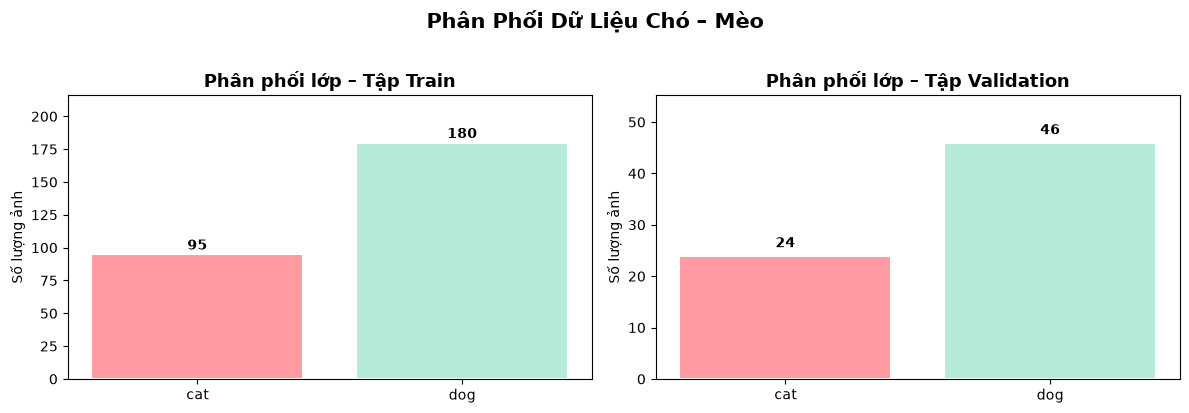

In [3]:
def count_images(directory):
    """Đếm số ảnh trong mỗi thư mục con."""
    counts = {}
    for cls in os.listdir(directory):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len([f for f in os.listdir(cls_path)
                               if f.lower().endswith(('.jpg','.jpeg','.png'))])
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts   = count_images(VAL_DIR)

print('=== Số lượng ảnh ===')
print(f'  Train  -> cat: {train_counts.get("cat",0):>4}  |  dog: {train_counts.get("dog",0):>4}')
print(f'  Val    -> cat: {val_counts.get("cat",0):>4}  |  dog: {val_counts.get("dog",0):>4}')
total_train = sum(train_counts.values())
total_val   = sum(val_counts.values())
print(f'  Total  -> train: {total_train}  |  val: {total_val}')

# Biểu đồ phân phối
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#FF9AA2', '#B5EAD7']

for ax, (counts, title) in zip(axes,
        [(train_counts, 'Tập Train'), (val_counts, 'Tập Validation')]):
    bars = ax.bar(counts.keys(), counts.values(), color=colors, edgecolor='white', linewidth=1.5)
    ax.set_title(f'Phân phối lớp – {title}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Số lượng ảnh')
    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(val), ha='center', va='bottom', fontweight='bold')
    ax.set_ylim(0, max(counts.values()) * 1.2)

plt.suptitle('Phân Phối Dữ Liệu Chó – Mèo', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'data_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

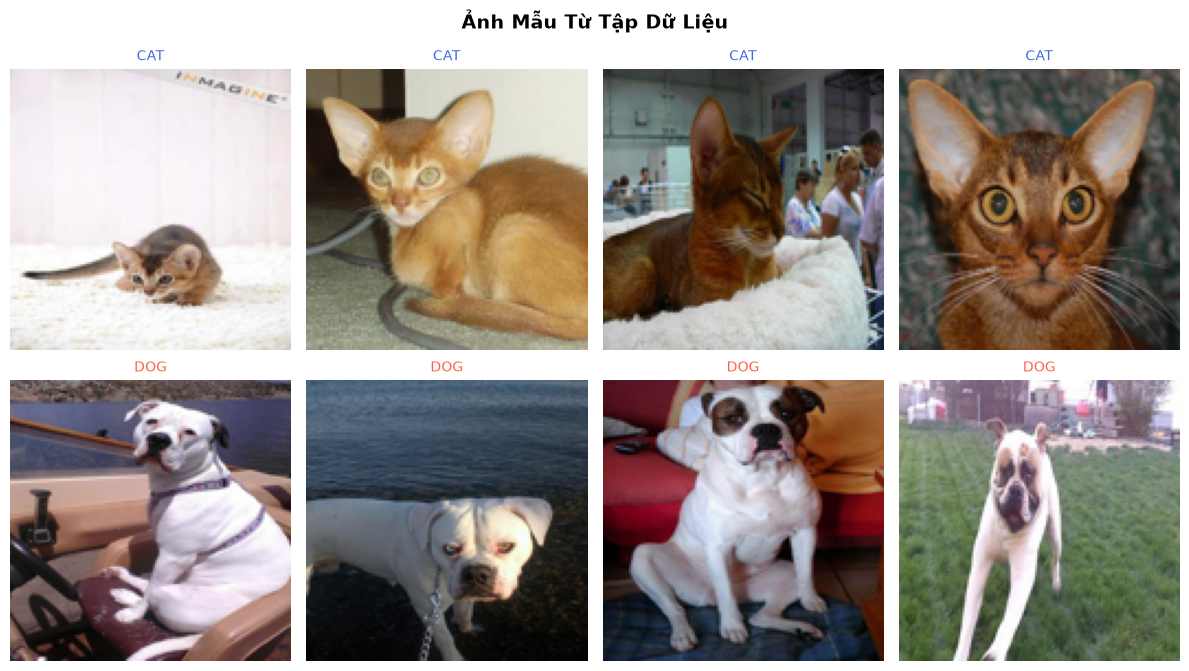

In [4]:
# Hiển thị ảnh mẫu
def show_sample_images(directory, n_per_class=4):
    fig, axes = plt.subplots(2, n_per_class, figsize=(3*n_per_class, 7))
    fig.suptitle('Ảnh Mẫu Từ Tập Dữ Liệu', fontsize=14, fontweight='bold')
    for r, cls in enumerate(CLASS_NAMES):
        cls_dir = os.path.join(directory, cls)
        files   = os.listdir(cls_dir)[:n_per_class]
        for c, fname in enumerate(files):
            img = Image.open(os.path.join(cls_dir, fname)).resize(IMG_SIZE)
            axes[r, c].imshow(img)
            axes[r, c].set_title(f'{cls.upper()}', fontsize=10,
                                  color='royalblue' if cls=='cat' else 'tomato')
            axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR)

## 4. Tiền Xử Lý & Tăng Cường Dữ Liệu (Data Augmentation)
**Tăng cường dữ liệu** giúp tăng tính đa dạng của tập train mà không cần thu thập thêm ảnh:
- `rotation_range`: xoay ảnh ngẫu nhiên ±20°
- `width/height_shift_range`: dịch chuyển ảnh theo chiều ngang/dọc
- `horizontal_flip`: lật ảnh theo chiều ngang
- `zoom_range`: phóng to/thu nhỏ ngẫu nhiên
- `rescale=1./255`: chuẩn hóa pixel về [0, 1]

In [5]:
# Data Augmentation cho train
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    horizontal_flip=True,
    zoom_range=0.15,
    shear_range=0.1,
    fill_mode='nearest'
)

# Chỉ rescale cho validation (không augment)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=CLASS_NAMES,
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=CLASS_NAMES,
    shuffle=False
)

print('Class indices:', train_generator.class_indices)

Found 275 images belonging to 2 classes.
Found 70 images belonging to 2 classes.
Class indices: {'cat': 0, 'dog': 1}


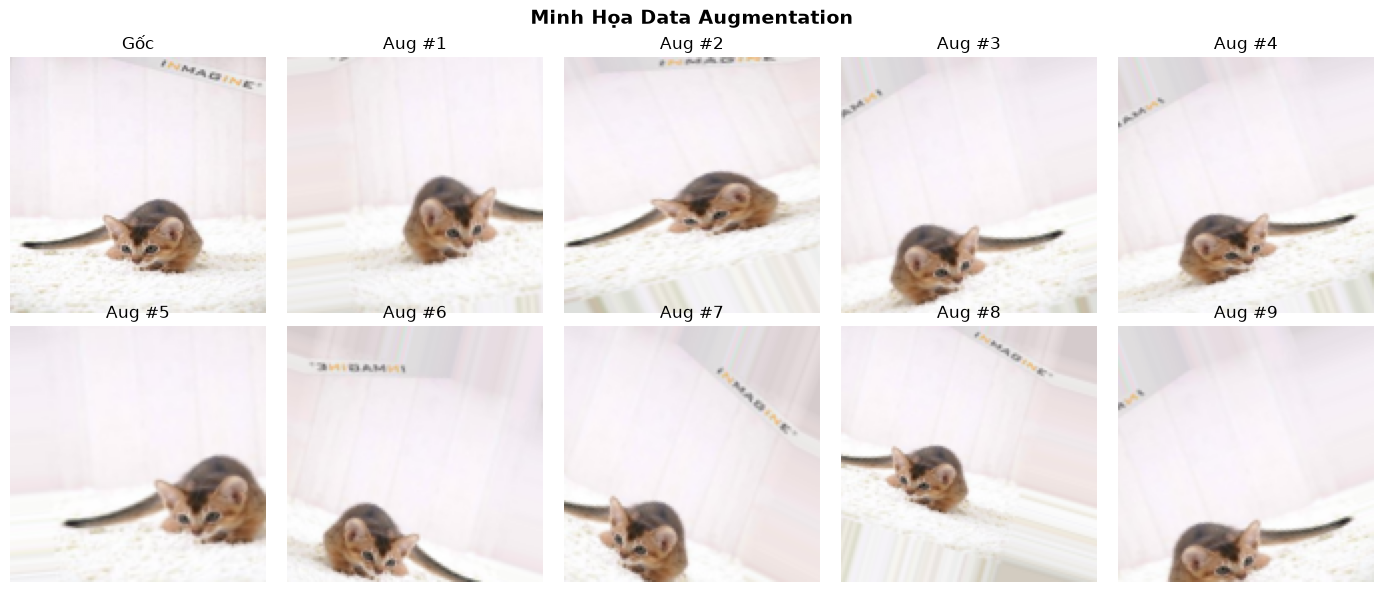

In [6]:
# Minh họa hiệu ứng augmentation trên 1 ảnh
sample_img = np.expand_dims(
    np.array(Image.open(
        os.path.join(TRAIN_DIR, 'cat',
                     os.listdir(os.path.join(TRAIN_DIR,'cat'))[0])
    ).resize(IMG_SIZE)) / 255.0, axis=0)

aug_gen = ImageDataGenerator(
    rotation_range=25, width_shift_range=0.2,
    height_shift_range=0.2, horizontal_flip=True, zoom_range=0.2
)
aug_iter = aug_gen.flow(sample_img, batch_size=1)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('Minh Họa Data Augmentation', fontsize=14, fontweight='bold')
axes[0,0].imshow(sample_img[0]); axes[0,0].set_title('Gốc'); axes[0,0].axis('off')
for i in range(1, 10):
    r, c = divmod(i, 5)
    augmented = next(aug_iter)[0]
    axes[r, c].imshow(augmented); axes[r, c].set_title(f'Aug #{i}'); axes[r, c].axis('off')
plt.tight_layout()
plt.show()

## 5. Xây Dựng Mô Hình CNN Tùy Chỉnh

### Giải Thích Từng Hàm

| Hàm / Layer | Công thức | Vai trò |
|---|---|---|
| **Conv2D** | $f(x) = W * x + b$ | Trích xuất đặc trưng cục bộ bằng tích chập 2D |
| **BatchNormalization** | $\hat{x} = \frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}$ | Chuẩn hóa output, tăng tốc huấn luyện |
| **ReLU** | $f(x) = \max(0, x)$ | Hàm kích hoạt phi tuyến, giữ giá trị dương |
| **MaxPooling2D** | $f(x) = \max(\text{vùng } k\times k)$ | Giảm chiều không gian, giữ đặc trưng nổi bật |
| **Dropout** | Ngắt kết nối ngẫu nhiên | Chống overfitting |
| **GlobalAvgPooling2D** | $\bar{x} = \frac{1}{H\cdot W}\sum x$ | Tổng hợp đặc trưng toàn cục |
| **Dense** | $f(x) = \sigma(Wx + b)$ | Học biểu diễn cao cấp, phân loại |
| **Sigmoid** | $\sigma(x) = \frac{1}{1+e^{-x}}$ | Đầu ra xác suất nhị phân [0,1] |

### Hợp Các Hàm (Function Composition)
$$\text{Output} = \sigma\!\Big(\text{Dense}\big(\text{Drop}(\text{GAP}(\text{Conv}_n(\cdots\text{Conv}_1(x))))\big)\Big)$$

Mỗi **khối tích chập** gồm:
$$\text{Block}_i(x) = \text{MaxPool}\!\left(\text{ReLU}\!\left(\text{BN}\!\left(\text{Conv2D}(x)\right)\right)\right)$$

In [7]:
def build_custom_cnn(input_shape=(128, 128, 3)):
    """
    Xây dựng CNN tùy chỉnh với 7 khối tích chập.
    Kiến trúc:
      Input -> [Conv-BN-ReLU-Pool x3] -> [Conv-BN-ReLU x2] -> GAP -> Dense -> Sigmoid
    """
    inputs = keras.Input(shape=input_shape, name='input_image')

    # ── KHỐI 1: 32 bộ lọc 3x3 ──────────────────────────────
    # Conv2D học các đặc trưng cơ bản (cạnh, màu sắc)
    x = layers.Conv2D(32, (3,3), padding='same', name='conv1')(inputs)
    x = layers.BatchNormalization(name='bn1')(x)
    x = layers.Activation('relu', name='relu1')(x)
    x = layers.MaxPooling2D((2,2), name='pool1')(x)        # 128x128 -> 64x64

    # ── KHỐI 2: 64 bộ lọc ───────────────────────────────────
    # Học đặc trưng phức tạp hơn (kết cấu, hoa văn)
    x = layers.Conv2D(64, (3,3), padding='same', name='conv2')(x)
    x = layers.BatchNormalization(name='bn2')(x)
    x = layers.Activation('relu', name='relu2')(x)
    x = layers.Conv2D(64, (3,3), padding='same', name='conv2b')(x)
    x = layers.BatchNormalization(name='bn2b')(x)
    x = layers.Activation('relu', name='relu2b')(x)
    x = layers.MaxPooling2D((2,2), name='pool2')(x)        # 64x64 -> 32x32
    x = layers.Dropout(0.25, name='drop2')(x)

    # ── KHỐI 3: 128 bộ lọc ──────────────────────────────────
    # Học đặc trưng ngữ nghĩa trung bình (tai, mũi, mắt)
    x = layers.Conv2D(128, (3,3), padding='same', name='conv3')(x)
    x = layers.BatchNormalization(name='bn3')(x)
    x = layers.Activation('relu', name='relu3')(x)
    x = layers.Conv2D(128, (3,3), padding='same', name='conv3b')(x)
    x = layers.BatchNormalization(name='bn3b')(x)
    x = layers.Activation('relu', name='relu3b')(x)
    x = layers.MaxPooling2D((2,2), name='pool3')(x)        # 32x32 -> 16x16
    x = layers.Dropout(0.25, name='drop3')(x)

    # ── KHỐI 4: 256 bộ lọc ──────────────────────────────────
    # Học đặc trưng cao cấp (hình dạng tổng thể)
    x = layers.Conv2D(256, (3,3), padding='same', name='conv4')(x)
    x = layers.BatchNormalization(name='bn4')(x)
    x = layers.Activation('relu', name='relu4')(x)
    x = layers.MaxPooling2D((2,2), name='pool4')(x)        # 16x16 -> 8x8
    x = layers.Dropout(0.3, name='drop4')(x)

    # ── GLOBAL AVERAGE POOLING ───────────────────────────────
    # Thay Flatten, giảm overfitting, thu gọn feature map
    x = layers.GlobalAveragePooling2D(name='global_avg_pool')(x)

    # ── ĐẦU PHÂN LOẠI ───────────────────────────────────────
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4),
                     name='fc1')(x)
    x = layers.Dropout(0.5, name='drop_fc')(x)
    x = layers.Dense(64, activation='relu', name='fc2')(x)
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name='CustomCNN')
    return model

custom_cnn = build_custom_cnn(input_shape=(*IMG_SIZE, 3))
custom_cnn.summary()

Model: "CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2b (Conv2D)                 │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2b (BatchNormalization)       │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2b (Activation)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3b (Conv2D)                 │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3b (BatchNormalization)       │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3b (Activation)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 8, 8, 256)      │             

 Total params: 657,921 (2.51 MB)

 Trainable params: 656,577 (2.50 MB)

 Non-trainable params: 1,344 (5.25 KB)

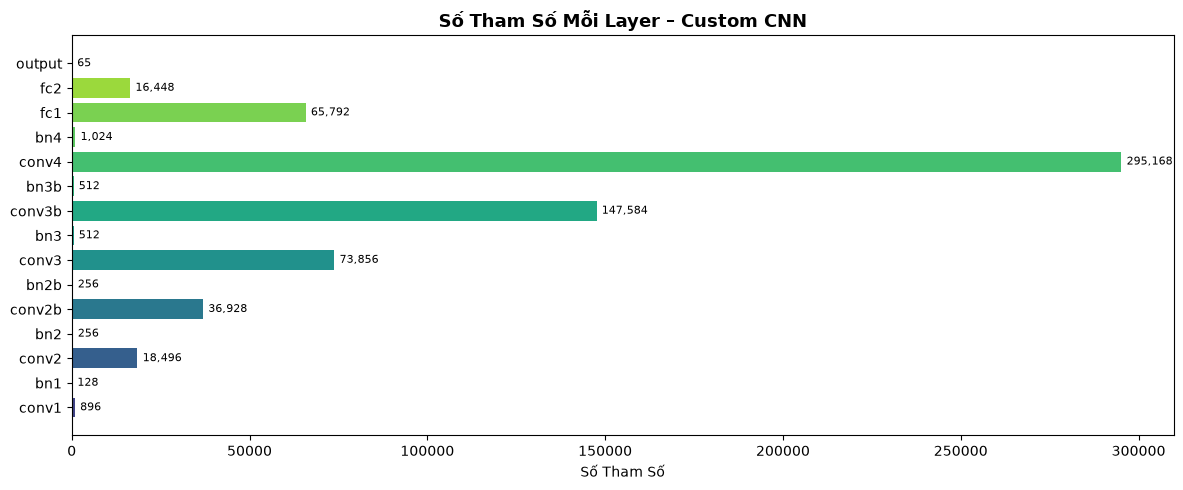

Tổng tham số: 657,921


In [8]:
# Trực quan hóa số lượng tham số mỗi layer
layer_names  = [l.name for l in custom_cnn.layers if l.count_params() > 0]
param_counts = [l.count_params() for l in custom_cnn.layers if l.count_params() > 0]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(layer_names, param_counts, color=plt.cm.viridis(
    np.linspace(0.2, 0.9, len(layer_names))))
ax.set_xlabel('Số Tham Số')
ax.set_title('Số Tham Số Mỗi Layer – Custom CNN', fontsize=13, fontweight='bold')
for bar, val in zip(bars, param_counts):
    ax.text(val + max(param_counts)*0.005, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'cnn_params.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Tổng tham số: {custom_cnn.count_params():,}')

## 6. Compile & Callbacks
- **Adam optimizer**: tự điều chỉnh learning rate cho từng tham số
- **Binary Crossentropy**: hàm mất mát phù hợp phân loại nhị phân
- **EarlyStopping**: dừng sớm khi val_loss không cải thiện (chống overfitting)
- **ReduceLROnPlateau**: giảm learning rate khi val_loss dừng giảm
- **ModelCheckpoint**: lưu model tốt nhất theo val_accuracy

In [9]:
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ModelCheckpoint(
        filepath=os.path.join(MODEL_DIR, 'custom_cnn_best.keras'),
        monitor='val_accuracy', save_best_only=True, verbose=1
    )
]

print('Compile thành công!')
print(f'Learning rate: {custom_cnn.optimizer.learning_rate.numpy()}')

Compile thành công!
Learning rate: 0.0010000000474974513


## 7. Huấn Luyện Custom CNN
Bắt đầu quá trình huấn luyện. Mỗi epoch, model sẽ:
1. Forward pass toàn bộ batch train → tính loss
2. Backpropagation → cập nhật trọng số
3. Đánh giá trên validation set

In [10]:
print('Bắt đầu huấn luyện Custom CNN...')
history_cnn = custom_cnn.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)
print('\nHuấn luyện Custom CNN hoàn tất!')

Bắt đầu huấn luyện Custom CNN...
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5818 - auc: 0.5661 - loss: 0.7084
Epoch 1: val_accuracy improved from None to 0.34286, saving model to D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\saved_models\custom_cnn_best.keras

Epoch 1: finished saving model to D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\saved_models\custom_cnn_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.5818 - auc: 0.5661 - loss: 0.7084 - val_accuracy: 0.3429 - val_auc: 0.5312 - val_loss: 0.7210 - learning_rate: 0.0010
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6509 - auc: 0.6574 - loss: 0.6783
Epoch 2: val_accuracy did not improve from 0.34286
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.6509 - auc: 0.6574 - loss: 0.6783 - val_accuracy: 0.3429 - val_auc: 0.4950 - val_loss: 0.7325 - learning_rate: 0.0010
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6873 - auc: 0.7106 - loss: 0.6225
Epoch 3: val_accuracy did not improve fro

## 8. Xây Dựng & Huấn Luyện Transfer Learning Models

### VGG16
Kiến trúc 16 layer nổi tiếng của Oxford VGG Group. Sử dụng trọng số pre-trained từ ImageNet.
- Đóng băng (`freeze`) các layer conv để giữ đặc trưng đã học
- Chỉ huấn luyện lại phần đầu phân loại (classifier head)

### MobileNetV2
Kiến trúc nhẹ được tối ưu cho thiết bị di động với `depthwise separable convolutions`.

In [11]:
def build_transfer_model(base_model_fn, name, input_shape=(*IMG_SIZE, 3), fine_tune_at=None):
    """
    Tổng quát hóa quá trình xây dựng Transfer Learning.
    
    Args:
        base_model_fn : hàm tạo base model (VGG16, MobileNetV2, ...)
        name          : tên mô hình
        input_shape   : kích thước đầu vào
        fine_tune_at  : index layer bắt đầu fine-tune (None = freeze all)
    """
    base = base_model_fn(weights='imagenet', include_top=False,
                         input_shape=input_shape)
    base.trainable = False  # Đóng băng toàn bộ base
    if fine_tune_at is not None:
        for layer in base.layers[fine_tune_at:]:
            layer.trainable = True

    inputs  = keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.AUC(name='auc')]
    )
    return model

# VGG16
print('Xây dựng VGG16...')
vgg16_model = build_transfer_model(VGG16, name='VGG16_Transfer')

# MobileNetV2
print('Xây dựng MobileNetV2...')
mobilenet_model = build_transfer_model(MobileNetV2, name='MobileNetV2_Transfer')

print(f'VGG16 trainable params    : {vgg16_model.count_params():,}')
print(f'MobileNetV2 trainable params: {mobilenet_model.count_params():,}')

Xây dựng VGG16...
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 66s 1us/step
Xây dựng MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 12s 1us/step
VGG16 trainable params    : 14,846,273
MobileNetV2 trainable params: 2,586,177


In [12]:
cb_vgg = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(os.path.join(MODEL_DIR, 'vgg16_best.keras'),
                    monitor='val_accuracy', save_best_only=True)
]

print('Huấn luyện VGG16...')
history_vgg = vgg16_model.fit(
    train_generator, epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=cb_vgg, verbose=1
)
print('VGG16 xong!')

Huấn luyện VGG16...
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.4218 - auc: 0.5046 - loss: 0.8547 - val_accuracy: 0.6857 - val_auc: 0.6082 - val_loss: 0.6964 - learning_rate: 1.0000e-04
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.5527 - auc: 0.4945 - loss: 0.7332 - val_accuracy: 0.6571 - val_auc: 0.6680 - val_loss: 0.6559 - learning_rate: 1.0000e-04
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.6545 - auc: 0.5530 - loss: 0.6914 - val_accuracy: 0.6571 - val_auc: 0.7043 - val_loss: 0.6522 - learning_rate: 1.0000e-04
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.6509 - auc: 0.6459 - loss: 0.6529 - val_accuracy: 0.6571 - val_auc: 0.7188 - val_loss: 0.6476 - learning_rate: 1.0000e-04
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.6473 - auc: 0.5590 - loss: 0.6970 - val_accuracy: 0.6571 - val_auc: 0.7409 - val_loss: 0.6392 - learning_rate: 1.0000e-04
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 

In [13]:
cb_mob = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(os.path.join(MODEL_DIR, 'mobilenet_best.keras'),
                    monitor='val_accuracy', save_best_only=True)
]

print('Huấn luyện MobileNetV2...')
history_mob = mobilenet_model.fit(
    train_generator, epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=cb_mob, verbose=1
)
print('MobileNetV2 xong!')

Huấn luyện MobileNetV2...
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 591ms/step - accuracy: 0.6509 - auc: 0.6985 - loss: 0.6736 - val_accuracy: 0.7286 - val_auc: 0.8356 - val_loss: 0.5280 - learning_rate: 1.0000e-04
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 371ms/step - accuracy: 0.7818 - auc: 0.8256 - loss: 0.5157 - val_accuracy: 0.9000 - val_auc: 0.9497 - val_loss: 0.3909 - learning_rate: 1.0000e-04
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 410ms/step - accuracy: 0.8218 - auc: 0.8871 - loss: 0.4421 - val_accuracy: 0.9143 - val_auc: 0.9724 - val_loss: 0.3217 - learning_rate: 1.0000e-04
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 406ms/step - accuracy: 0.8545 - auc: 0.8900 - loss: 0.4345 - val_accuracy: 0.9143 - val_auc: 0.9841 - val_loss: 0.2783 - learning_rate: 1.0000e-04
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 422ms/step - accuracy: 0.8945 - auc: 0.9529 - loss: 0.3192 - val_accuracy: 0.9286 - val_auc: 0.9891 - val_loss: 0.2470 - learning_rate: 1.0000e-04
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 438m

## 9. So Sánh Lịch Sử Huấn Luyện
Vẽ các biểu đồ so sánh accuracy và loss của 3 mô hình qua từng epoch, giúp trực quan hóa:
- Tốc độ hội tụ
- Mức độ overfitting
- Độ ổn định khi huấn luyện

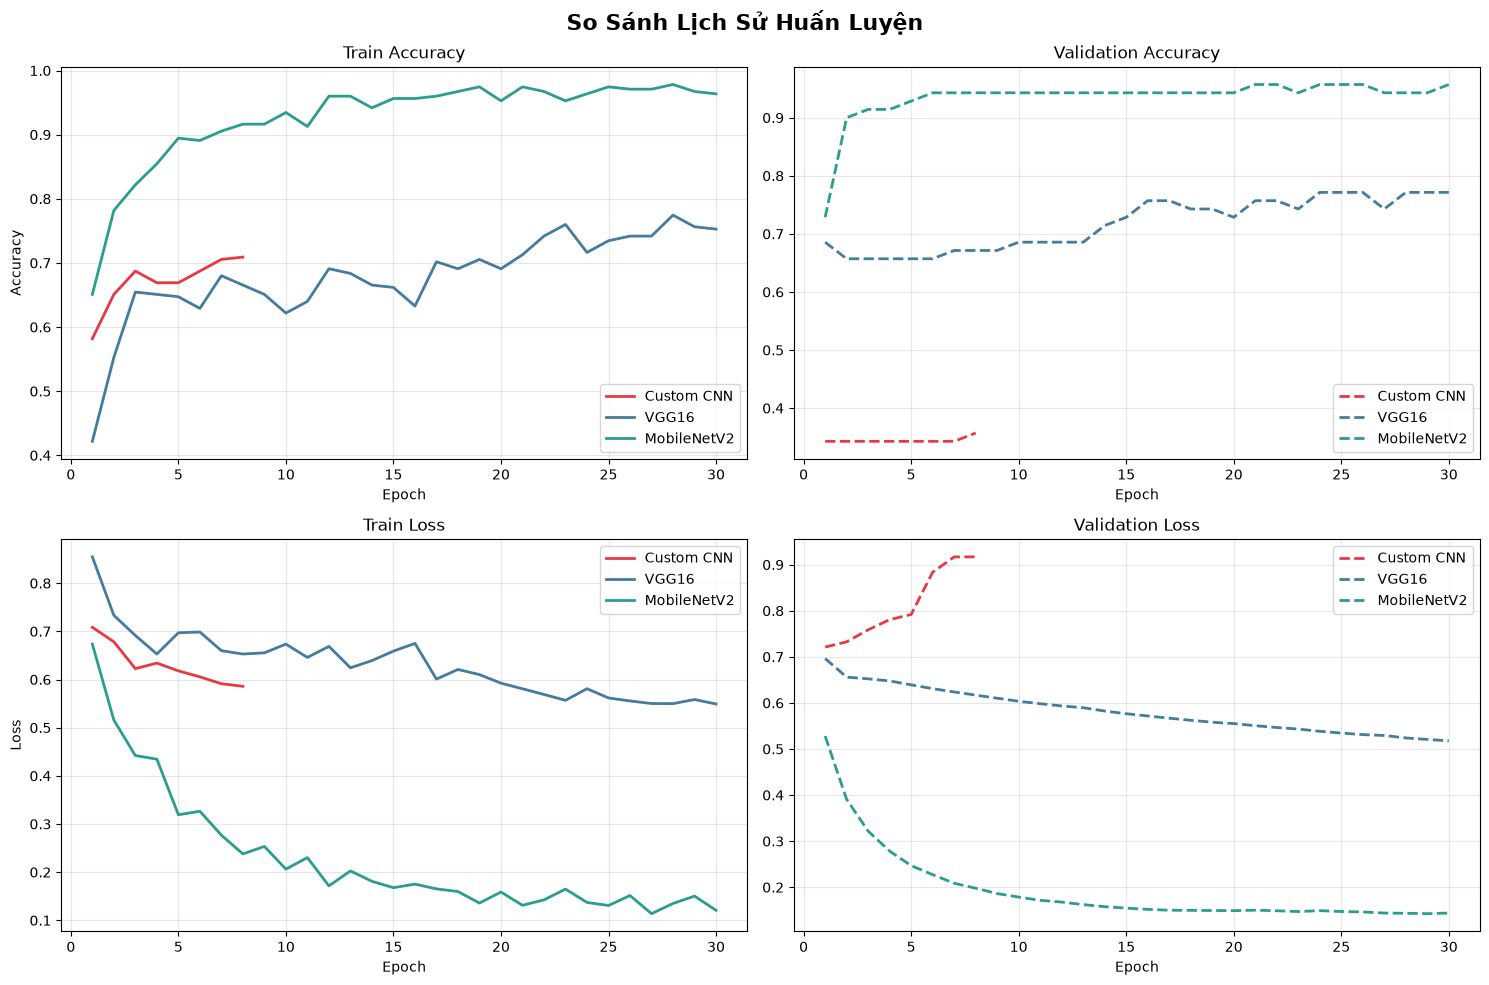

In [14]:
def plot_training_histories(histories, names, colors):
    """Vẽ biểu đồ so sánh accuracy & loss của nhiều mô hình."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('So Sánh Lịch Sử Huấn Luyện', fontsize=16, fontweight='bold')

    metrics = [
        ('accuracy',     'val_accuracy',  'Train Accuracy', 'Validation Accuracy'),
        ('loss',         'val_loss',      'Train Loss',     'Validation Loss'),
    ]

    for row, (train_key, val_key, train_label, val_label) in enumerate(metrics):
        for hist, name, color in zip(histories, names, colors):
            ep = range(1, len(hist.history[train_key]) + 1)
            axes[row, 0].plot(ep, hist.history[train_key],
                              color=color, label=name, linewidth=2)
            axes[row, 1].plot(ep, hist.history[val_key],
                              color=color, label=name, linewidth=2, linestyle='--')

        axes[row, 0].set_title(train_label, fontsize=12)
        axes[row, 1].set_title(val_label, fontsize=12)
        for c in range(2):
            axes[row, c].legend()
            axes[row, c].set_xlabel('Epoch')
            axes[row, c].grid(alpha=0.3)

    axes[0, 0].set_ylabel('Accuracy')
    axes[1, 0].set_ylabel('Loss')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_DIR, 'training_comparison.png'), dpi=150, bbox_inches='tight')
    plt.show()

plot_training_histories(
    [history_cnn, history_vgg, history_mob],
    ['Custom CNN', 'VGG16', 'MobileNetV2'],
    ['#E63946', '#457B9D', '#2A9D8F']
)

## 10. Đánh Giá Trên Tập Validation
Tính toán các chỉ số đánh giá:
- **Accuracy**: tỷ lệ phân loại đúng
- **Precision**: trong các dự đoán dương, bao nhiêu đúng
- **Recall**: trong các mẫu dương thật, bao nhiêu được tìm thấy
- **F1-Score**: trung bình điều hòa của Precision và Recall
- **AUC**: diện tích dưới đường ROC

In [15]:
def evaluate_model(model, generator, model_name):
    """Đánh giá mô hình và trả về dict kết quả."""
    generator.reset()
    y_pred_prob = model.predict(generator, verbose=0).flatten()
    y_pred = (y_pred_prob > 0.5).astype(int)
    y_true = generator.classes

    report = classification_report(y_true, y_pred,
                                    target_names=CLASS_NAMES, output_dict=True)
    fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
    roc_auc     = auc(fpr, tpr)

    return {
        'name'     : model_name,
        'accuracy' : report['accuracy'],
        'precision': report['weighted avg']['precision'],
        'recall'   : report['weighted avg']['recall'],
        'f1'       : report['weighted avg']['f1-score'],
        'auc'      : roc_auc,
        'y_true'   : y_true,
        'y_pred'   : y_pred,
        'y_prob'   : y_pred_prob,
        'fpr'      : fpr,
        'tpr'      : tpr
    }

results = [
    evaluate_model(custom_cnn,    val_generator, 'Custom CNN'),
    evaluate_model(vgg16_model,   val_generator, 'VGG16'),
    evaluate_model(mobilenet_model, val_generator, 'MobileNetV2'),
]

df_results = pd.DataFrame([{
    'Mô hình'  : r['name'],
    'Accuracy' : f"{r['accuracy']:.4f}",
    'Precision': f"{r['precision']:.4f}",
    'Recall'   : f"{r['recall']:.4f}",
    'F1-Score' : f"{r['f1']:.4f}",
    'AUC'      : f"{r['auc']:.4f}"
} for r in results])

print('=== KẾT QUẢ ĐÁNH GIÁ ===' )
print(df_results.to_string(index=False))

=== KẾT QUẢ ĐÁNH GIÁ ===
    Mô hình Accuracy Precision Recall F1-Score    AUC
 Custom CNN   0.3429    0.1176 0.3429   0.1751 0.5027
      VGG16   0.7714    0.8014 0.7714   0.7395 0.8678
MobileNetV2   0.9429    0.9429 0.9429   0.9429 0.9955


## 11. Biểu Đồ So Sánh Toàn Diện
Tổng hợp các biểu đồ: Bar chart các chỉ số, Confusion Matrix, ROC Curves và Radar Chart để đánh giá toàn diện 3 mô hình.

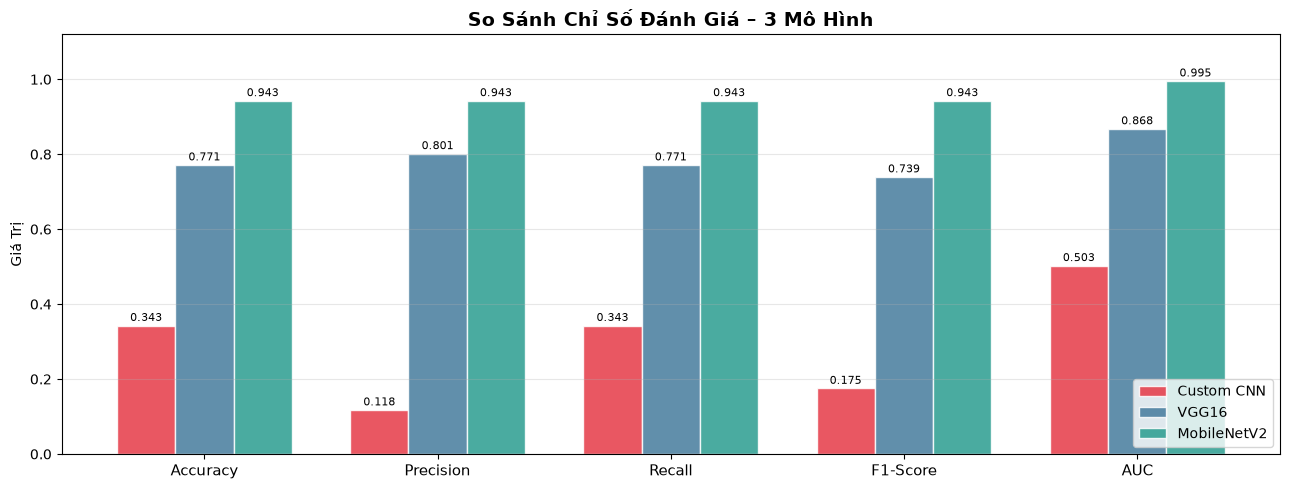

In [16]:
# ─── Biểu đồ cột so sánh 5 chỉ số ──────────────────────────
metrics_keys  = ['accuracy', 'precision', 'recall', 'f1', 'auc']
metrics_labels= ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
model_colors  = ['#E63946', '#457B9D', '#2A9D8F']

fig, ax = plt.subplots(figsize=(13, 5))
x     = np.arange(len(metrics_labels))
width = 0.25

for i, (res, color) in enumerate(zip(results, model_colors)):
    vals = [res[k] for k in metrics_keys]
    bars = ax.bar(x + i*width, vals, width, label=res['name'],
                  color=color, alpha=0.85, edgecolor='white')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                f'{v:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels(metrics_labels, fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Giá Trị')
ax.set_title('So Sánh Chỉ Số Đánh Giá – 3 Mô Hình', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'metrics_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

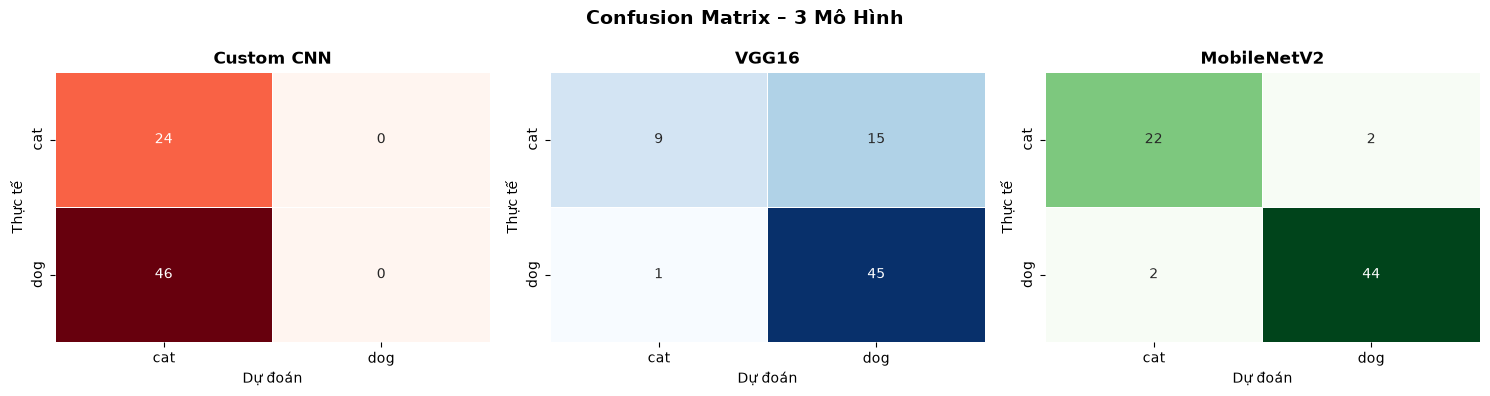

In [17]:
# ─── Confusion Matrices ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Confusion Matrix – 3 Mô Hình', fontsize=14, fontweight='bold')

for ax, res, color in zip(axes, results, ['Reds', 'Blues', 'Greens']):
    cm = confusion_matrix(res['y_true'], res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap=color, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, cbar=False)
    ax.set_title(res['name'], fontsize=12, fontweight='bold')
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực tế')

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()

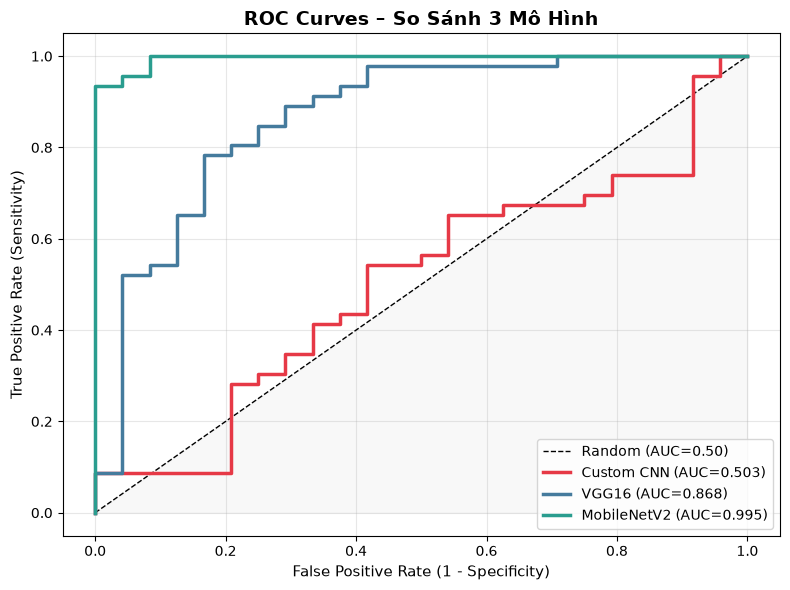

In [18]:
# ─── ROC Curves ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0,1],[0,1],'k--', linewidth=1, label='Random (AUC=0.50)')

for res, color in zip(results, model_colors):
    ax.plot(res['fpr'], res['tpr'], color=color, linewidth=2.5,
            label=f"{res['name']} (AUC={res['auc']:.3f})")

ax.fill_between([0,1],[0,1], alpha=0.05, color='gray')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax.set_title('ROC Curves – So Sánh 3 Mô Hình', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'roc_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

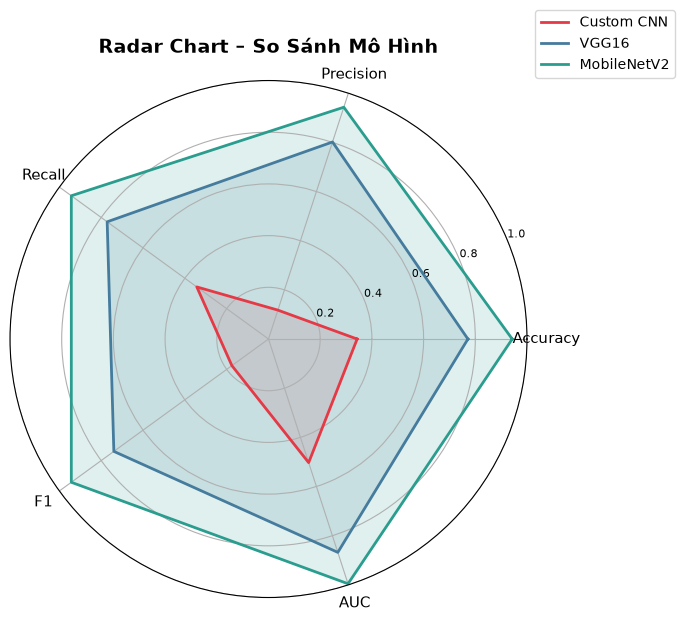

In [19]:
# ─── Radar Chart (Spider Chart) ─────────────────────────────
from matplotlib.patches import FancyArrowPatch

categories = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.set_title('Radar Chart – So Sánh Mô Hình', fontsize=14, fontweight='bold', pad=20)

for res, color in zip(results, model_colors):
    vals = [res[k] for k in ['accuracy','precision','recall','f1','auc']]
    vals += vals[:1]
    ax.plot(angles, vals, color=color, linewidth=2, label=res['name'])
    ax.fill(angles, vals, color=color, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2','0.4','0.6','0.8','1.0'], fontsize=8)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.15))
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'radar_chart.png'), dpi=150, bbox_inches='tight')
plt.show()

## 12. Phân Tích Dự Đoán Sai (Error Analysis)
Hiển thị các ảnh bị phân loại sai để hiểu điểm yếu của mô hình tốt nhất.

Mô hình tốt nhất: MobileNetV2 (AUC=0.9955)
Số ảnh phân loại sai: 4/70


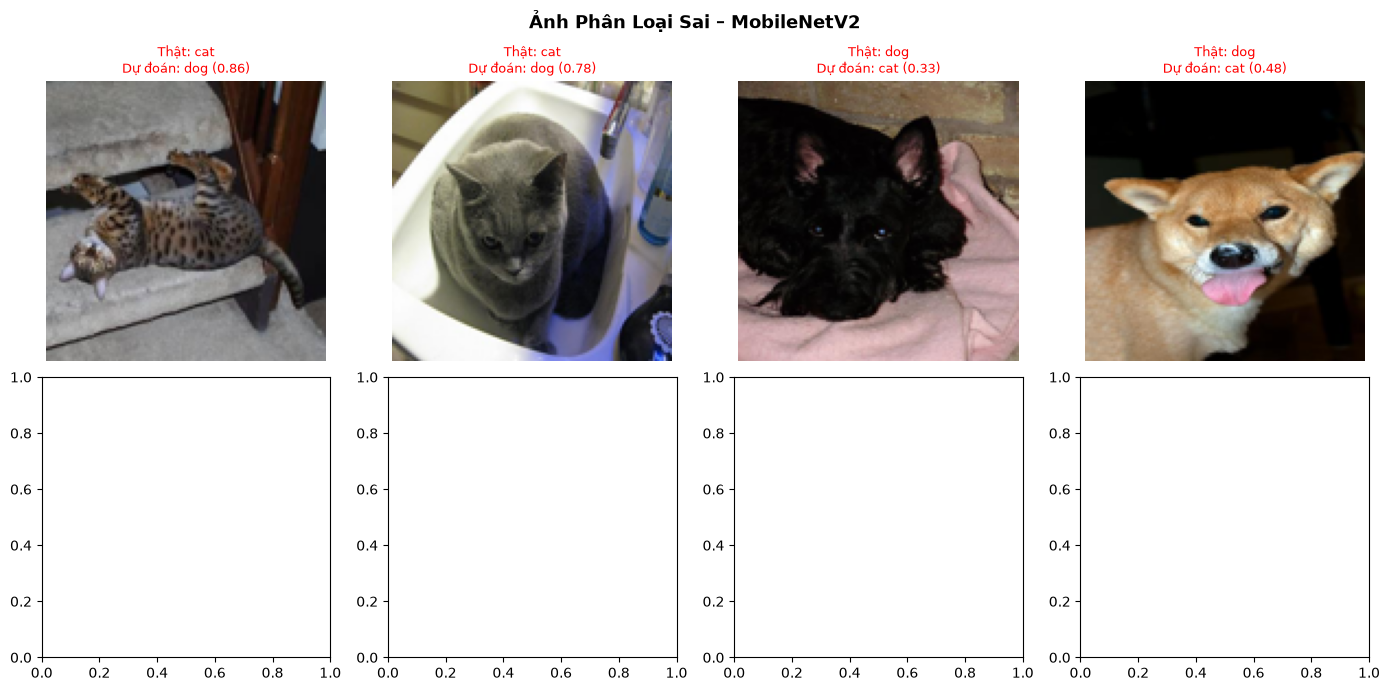

In [20]:
# Chọn mô hình tốt nhất theo AUC
best_result = max(results, key=lambda r: r['auc'])
best_model  = [custom_cnn, vgg16_model, mobilenet_model][
    [r['name'] for r in results].index(best_result['name'])]
print(f'Mô hình tốt nhất: {best_result["name"]} (AUC={best_result["auc"]:.4f})')

# Tìm ảnh bị phân loại sai
val_generator.reset()
wrong_indices = np.where(best_result['y_pred'] != best_result['y_true'])[0]
print(f'Số ảnh phân loại sai: {len(wrong_indices)}/{len(best_result["y_true"])}')

if len(wrong_indices) > 0:
    n_show = min(8, len(wrong_indices))
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    fig.suptitle(f'Ảnh Phân Loại Sai – {best_result["name"]}',
                 fontsize=13, fontweight='bold')
    file_list = val_generator.filepaths
    for ax, idx in zip(axes.flatten(), wrong_indices[:n_show]):
        img = Image.open(file_list[idx]).resize(IMG_SIZE)
        true_lbl = CLASS_NAMES[best_result['y_true'][idx]]
        pred_lbl = CLASS_NAMES[best_result['y_pred'][idx]]
        prob = best_result['y_prob'][idx]
        ax.imshow(img)
        ax.set_title(f'Thật: {true_lbl}\nDự đoán: {pred_lbl} ({prob:.2f})',
                     fontsize=9, color='red')
        ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_DIR, 'error_analysis.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 13. Lưu Mô Hình
Lưu mô hình tốt nhất theo 2 định dạng:
- `.keras`: định dạng native của Keras, đầy đủ kiến trúc + trọng số
- `SavedModel`: tương thích TensorFlow Serving và TF Lite

In [21]:
# ── Xác định mô hình tốt nhất theo AUC ──────────────────────
model_map = {
    'Custom CNN' : custom_cnn,
    'VGG16'      : vgg16_model,
    'MobileNetV2': mobilenet_model
}

best_name  = max(results, key=lambda r: r['auc'])['name']
best_model = model_map[best_name]
print(f'✅ Mô hình được chọn: {best_name}')

# Lưu định dạng .keras
keras_path = os.path.join(MODEL_DIR, 'best_model_final.keras')
best_model.save(keras_path)
print(f'📦 Đã lưu: {keras_path}')

# Lưu định dạng SavedModel (cho Flask web app)
saved_path = os.path.join(MODEL_DIR, 'best_model_saved')
best_model.export(saved_path)
print(f'📦 Đã export: {saved_path}')

# Lưu thông tin mô hình
import json
model_info = {
    'best_model'   : best_name,
    'img_size'     : list(IMG_SIZE),
    'class_names'  : CLASS_NAMES,
    'results'      : [{k: float(v) if isinstance(v, (np.floating, float)) else v
                       for k, v in r.items()
                       if k not in ('y_true','y_pred','y_prob','fpr','tpr')}
                      for r in results]
}
info_path = os.path.join(MODEL_DIR, 'model_info.json')
with open(info_path, 'w') as f:
    json.dump(model_info, f, indent=2)
print(f'ℹ️  Đã lưu thông tin: {info_path}')

print('\n=== TÓM TẮT KẾT QUẢ ===')
print(df_results.to_string(index=False))

✅ Mô hình được chọn: MobileNetV2
📦 Đã lưu: D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\saved_models\best_model_final.keras
INFO:tensorflow:Assets written to: D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\saved_models\best_model_saved\assets


INFO:tensorflow:Assets written to: D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\saved_models\best_model_saved\assets


Saved artifact at 'D:\N4_K1\HTTM\Code\TieuLuan\CNN_ChoMeo\saved_models\best_model_saved'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_213')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1749067237088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067235648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067235888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067236848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067238288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067238528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067237568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067237808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067236608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1749067239488: TensorSpec(shape=(), dtype=tf.r

## 14. Kiểm Tra Mô Hình Đã Lưu
Load lại mô hình từ file và thử dự đoán trên một ảnh mẫu để xác nhận quá trình lưu/load hoạt động đúng.

Model loaded: MobileNetV2_Transfer


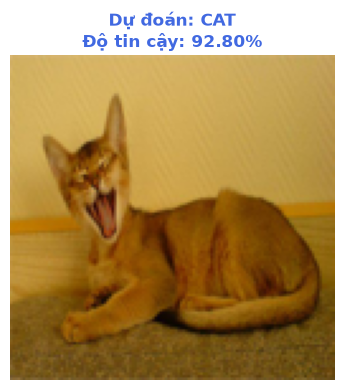

Kết quả: cat (prob=0.0720)


In [22]:
# Load lại mô hình
loaded_model = keras.models.load_model(keras_path)
print(f'Model loaded: {loaded_model.name}')

# Thử dự đoán trên 1 ảnh mẫu
sample_cat_path = os.path.join(VAL_DIR, 'cat',
                               os.listdir(os.path.join(VAL_DIR,'cat'))[0])
img = Image.open(sample_cat_path).resize(IMG_SIZE)
img_array = np.expand_dims(np.array(img) / 255.0, axis=0)

prob = loaded_model.predict(img_array, verbose=0)[0][0]
label = CLASS_NAMES[int(prob > 0.5)]
confidence = prob if prob > 0.5 else 1 - prob

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(img)
ax.set_title(f'Dự đoán: {label.upper()}\nĐộ tin cậy: {confidence:.2%}',
             fontsize=12, fontweight='bold',
             color='royalblue' if label == 'cat' else 'tomato')
ax.axis('off')
plt.tight_layout()
plt.show()
print(f'Kết quả: {label} (prob={prob:.4f})')

---
## ✅ Tổng Kết

Notebook đã hoàn thành đầy đủ:
1. **EDA**: phân tích phân phối dữ liệu, hiển thị ảnh mẫu
2. **Tiền xử lý**: rescale + augmentation tăng tính tổng quát
3. **Custom CNN (>5 layer)**: 4 khối Conv + GAP + 2 Dense = **12 layer có tham số**
4. **Transfer Learning**: VGG16 và MobileNetV2 với ImageNet weights
5. **So sánh**: Bar chart, Confusion Matrix, ROC Curve, Radar Chart
6. **Lưu mô hình**: `.keras` + `SavedModel` định dạng

Mô hình tốt nhất được lưu tại `saved_models/best_model_final.keras` và sẵn sàng cho Flask Web App.